# P06 — Balanço final: quantas células ficam, e quais

Compara os dois caminhos, biblioteca a biblioteca:

| | pré-processamento antigo (A01) | pré-processamento novo (P01–P05) |
| --- | --- | --- |
| ponto de partida | matriz filtrada do Cell Ranger | matriz raw, avaliada com emptyDrops e CellBender |
| quem é célula | Cell Ranger | Cell Ranger (≡ `emptyDropsCellRanger`) + barcodes de 200–500 UMIs com perfil de célula (P01, P03) |
| QC | spatools, MAD k = 5 só na cauda inferior; MT bruto | valor único de 200 UMIs em todas as bibliotecas + regras do best practices: limites superiores, top-20, MT em logit + 8%, sem material nuclear; fora do Cell Ranger, só barcodes com perfil de célula |
| RNA ambiente | — | SoupX |
| doublets | Scrublet automático, removidos | scDblFinder com limiar calibrado pela taxa do 10x + T + B validados, removidos |

e responde: o pré-processamento a partir da raw recupera células? Quantas,
onde, de que qualidade, e com que efeito nas citocinas?

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from functions import config, fmt as F, io, plotting, qcplots
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P06_balanco_final"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
T = config.TABLES

In [2]:
p01 = pd.read_csv(T / "P01_gotas_vazias" / "chamadas_por_biblioteca.csv", index_col=0).reindex(LIBS)
qc = io.load_data("P03_qc_best_practices", "qc_candidatos")
semel = pd.read_csv(T / "P01_gotas_vazias" / "semelhanca_com_celulas.csv", index_col=0).reindex(LIBS)
a01 = io.load_data("A01_preprocessamento", "celulas_qc")
nov = ad.read_h5ad(io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad"), backed="r")
obs = nov.obs.copy()
nov.file.close()


def _bool(s):
    return s.astype(str).str.lower().isin(["true", "1"])


lib_f = obs["library_id"].astype(str)
novo = pd.DataFrame({
    "barcodes com UMI": p01["barcodes_com_umi"],
    "Cell Ranger": qc.groupby("library_id")["cellranger"].sum().reindex(LIBS),
    "QC (200 UMIs; extras só com perfil de célula)": qc.groupby("library_id")["passa"].sum().reindex(LIBS),
    "sem doublets": lib_f.value_counts().reindex(LIBS),
}).fillna(0).astype(int)
alternativas = pd.DataFrame({
    "QC com MAD por biblioteca": qc.groupby("library_id")["passa_mad"].sum().reindex(LIBS),
    "QC com limiares literais (candidatos de todos os métodos)": qc.groupby("library_id")["passa_lit"].sum().reindex(LIBS),
    "recuperados pelo emptyDrops": semel["recuperados"],
    "estimativa dos recuperados com perfil de célula": semel["estimativa_com_perfil_de_celula"].round(0),
}).fillna(0).astype(int)
io.save_table(alternativas, NB, "alternativas", description="Contagens com as alternativas avaliadas e o teto de recuperação")
antigo = pd.DataFrame({
    "Cell Ranger": a01.groupby("library_id").size().reindex(LIBS),
    "filtro MAD (spatools)": a01.groupby("library_id")["passou_mad"].sum().reindex(LIBS),
    "Scrublet": a01.groupby("library_id")["mantida"].sum().reindex(LIBS),
}).astype(int)
io.save_table(novo, NB, "funil_novo", description="Células por etapa no pré-processamento novo (a partir da raw)")
io.save_table(antigo, NB, "funil_antigo", description="Células por etapa no pré-processamento antigo (A01)")
display(novo)
display(alternativas)
antigo

,barcodes com UMI,Cell Ranger,QC (200 UMIs; extras só com perfil de célula),sem doublets
library_id,,,,
CTH92_NS,1497038,851,866,860
CTH92_ML,1363786,1570,1592,1569
CTH94_NS,1668757,6090,5967,5669
CTH94_ML,1204510,547,545,535
CTH97_NS,1271948,1628,1566,1545
CTH97_ML,890760,4737,4849,4658
PB20_NS,1040305,635,636,626
PB20_ML,1072778,841,850,841
PB21_NS,1577066,4266,3913,3790


,QC com MAD por biblioteca,QC com limiares literais (candidatos de todos os métodos),recuperados pelo emptyDrops,estimativa dos recuperados com perfil de célula
library_id,,,,
CTH92_NS,822,839,89,78
CTH92_ML,1629,1757,106,102
CTH94_NS,5581,5753,609,279
CTH94_ML,515,613,105,31
CTH97_NS,1483,1376,5116,37
CTH97_ML,5273,5500,494,482
PB20_NS,636,678,86,52
PB20_ML,794,815,126,106
PB21_NS,3652,6508,21388,178


,Cell Ranger,filtro MAD (spatools),Scrublet
library_id,,,
CTH92_NS,851,812,809
CTH92_ML,1570,1538,1531
CTH94_NS,6090,5579,5576
CTH94_ML,547,500,499
CTH97_NS,1628,1517,1513
CTH97_ML,4737,4696,4696
PB20_NS,635,602,592
PB20_ML,841,781,777
PB21_NS,4266,3666,3665


## 1. O funil de cada caminho

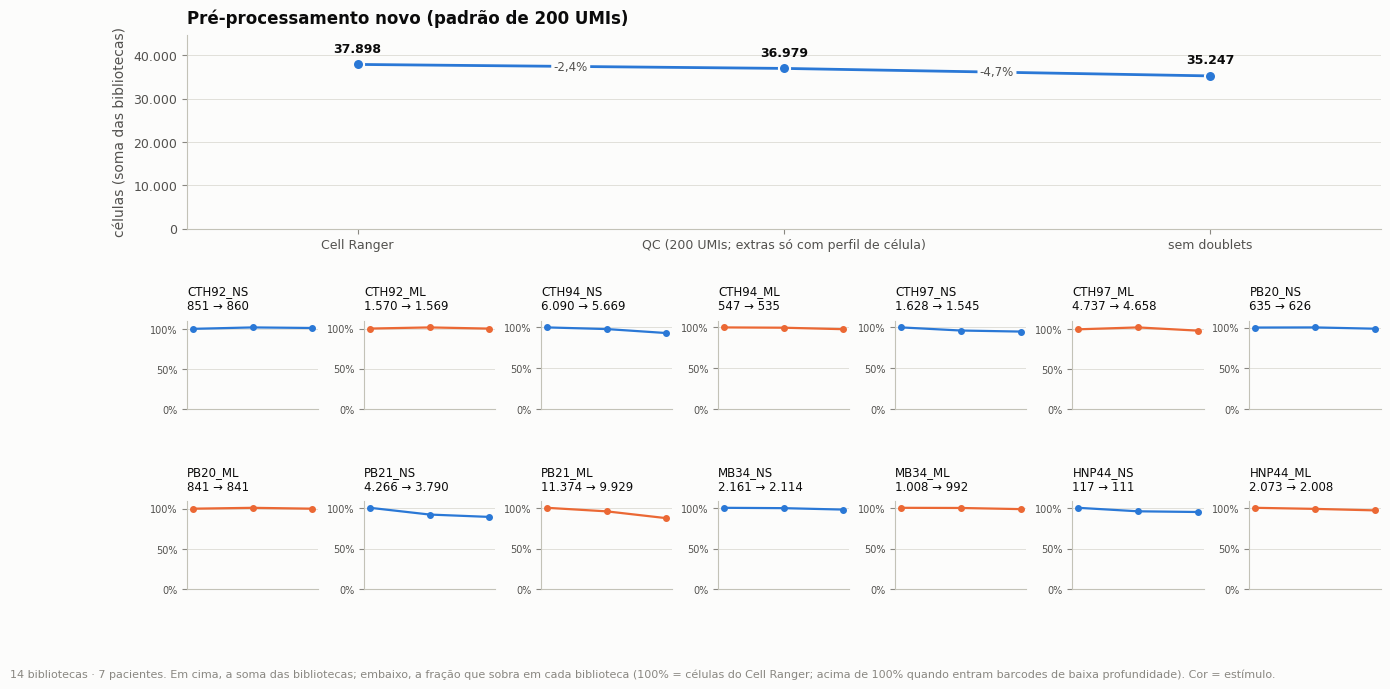

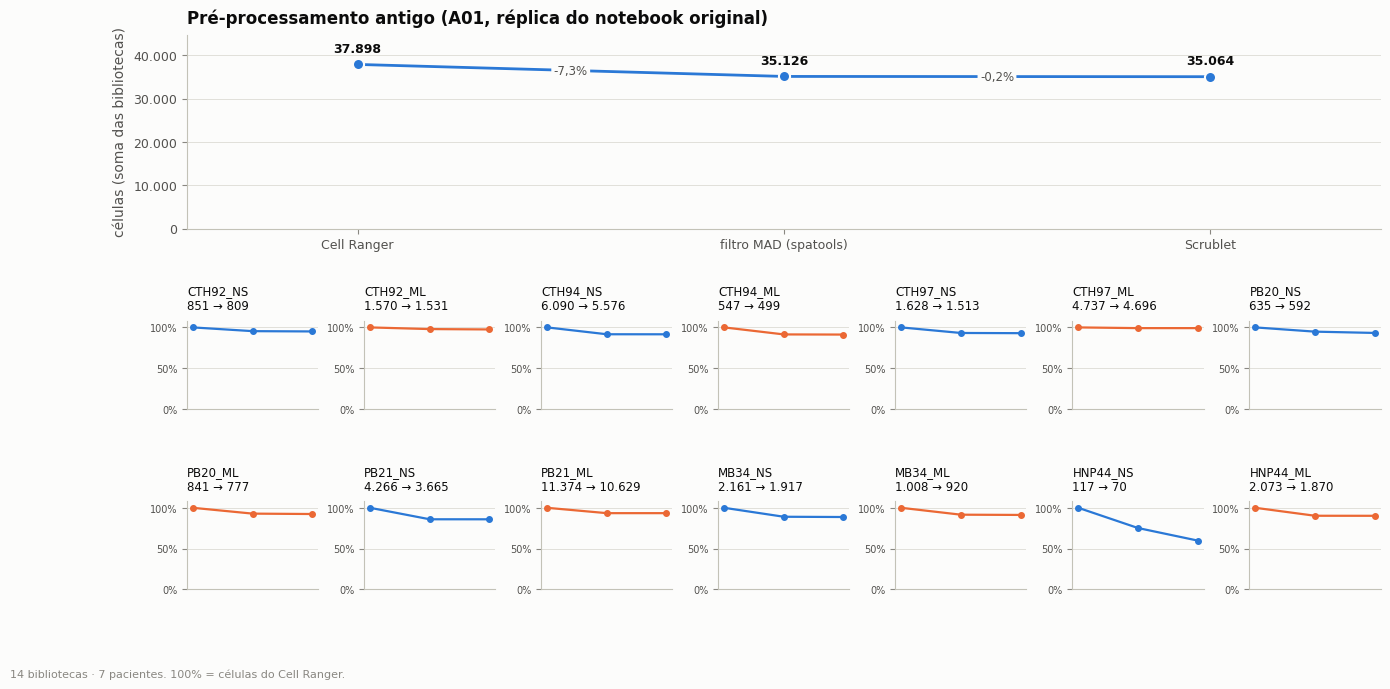

In [3]:
fig = qcplots.qc_funnel(novo.drop(columns="barcodes com UMI"), title=f"Pré-processamento novo (padrão de {config.QC_MIN_UMIS} UMIs)")
plotting.note(fig, f"{plotting.N_DESIGN}. Em cima, a soma das bibliotecas; embaixo, a fração que sobra em cada biblioteca "
                   "(100% = células do Cell Ranger; acima de 100% quando entram barcodes de baixa profundidade). Cor = estímulo.", y=0.0)
plotting.savefig(fig, NB, "funil_novo", description="Funil do pré-processamento novo", data=novo.reset_index(), data_index=False)
plt.show()
fig = qcplots.qc_funnel(antigo, title="Pré-processamento antigo (A01, réplica do notebook original)")
plotting.note(fig, f"{plotting.N_DESIGN}. 100% = células do Cell Ranger.", y=0.0)
plotting.savefig(fig, NB, "funil_antigo", description="Funil do pré-processamento antigo", data=antigo.reset_index(), data_index=False)
plt.show()

## 2. Antigo × novo, por biblioteca

In [4]:
fim_antigo = antigo["Scrublet"]
fim_qc = novo["QC (200 UMIs; extras só com perfil de célula)"]
fim_novo = novo["sem doublets"]
bp = _bool(obs["baixa_profundidade"])
so = _bool(obs["so_no_padrao"])
bal = pd.DataFrame({
    "Cell Ranger": antigo["Cell Ranger"],
    "final antigo": fim_antigo,
    "final novo": fim_novo,
    "diferença": fim_novo - fim_antigo,
    "variação": fim_novo / fim_antigo - 1,
    "baixa profundidade (fora do Cell Ranger)": bp.groupby(lib_f).sum().reindex(LIBS).fillna(0).astype(int),
    "do Cell Ranger que o MAD descartaria": so.groupby(lib_f).sum().reindex(LIBS).fillna(0).astype(int),
    "doublets removidos": fim_qc - fim_novo,
})
tot = bal.sum(numeric_only=True)
tot["variação"] = tot["final novo"] / tot["final antigo"] - 1
bal.loc["TOTAL"] = tot
io.save_table(bal, NB, "balanco_por_biblioteca", description="Células finais: pré-processamento antigo × novo, por biblioteca")
bal

,Cell Ranger,final antigo,final novo,diferença,variação,baixa profundidade (fora do Cell Ranger),do Cell Ranger que o MAD descartaria,doublets removidos
library_id,,,,,,,,
CTH92_NS,851.0,809.0,860.0,51.0,0.063041,21.0,24.0,6.0
CTH92_ML,1570.0,1531.0,1569.0,38.0,0.024820,50.0,0.0,23.0
CTH94_NS,6090.0,5576.0,5669.0,93.0,0.016679,100.0,286.0,298.0
CTH94_ML,547.0,499.0,535.0,36.0,0.072144,10.0,20.0,10.0
CTH97_NS,1628.0,1513.0,1545.0,32.0,0.021150,33.0,50.0,21.0
CTH97_ML,4737.0,4696.0,4658.0,-38.0,-0.008092,197.0,0.0,191.0
PB20_NS,635.0,592.0,626.0,34.0,0.057432,8.0,21.0,10.0
PB20_ML,841.0,777.0,841.0,64.0,0.082368,21.0,36.0,9.0
PB21_NS,4266.0,3665.0,3790.0,125.0,0.034106,81.0,180.0,123.0


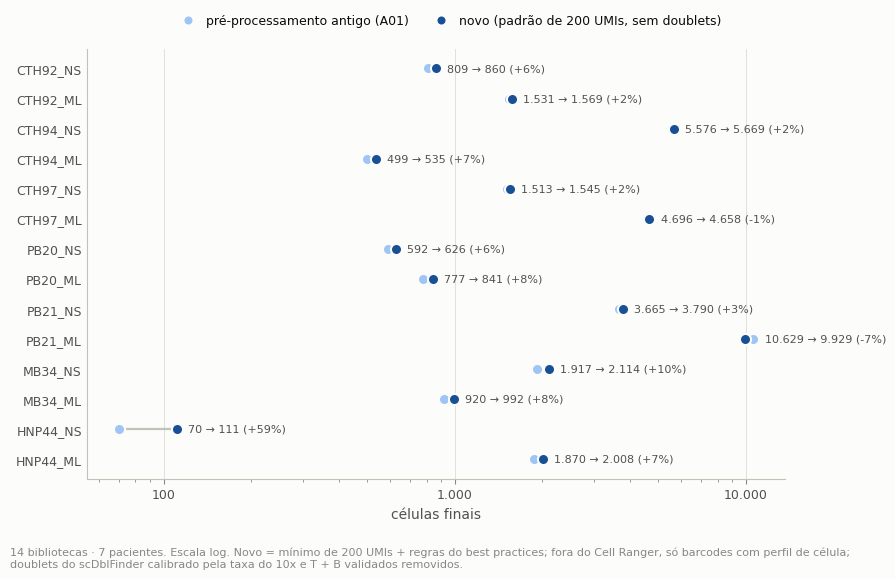

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.4))
plotting.dumbbell(ax, fim_antigo.astype(float), fim_novo.astype(float), xlabel="células finais", log=True,
                  labels=LIBS, before_label="pré-processamento antigo (A01)", after_label="novo",
                  value_fmt=lambda b, a: f"{F.n(b)} → {F.n(a)} ({F.pct(a / b - 1, 0, signed=True)})", legend=False)
fig.legend(handles=plotting.old_new_handles("pré-processamento antigo (A01)", f"novo (padrão de {config.QC_MIN_UMIS} UMIs, sem doublets)"),
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
plotting.note(fig, f"{plotting.N_DESIGN}. Escala log. Novo = mínimo de {config.QC_MIN_UMIS} UMIs + regras do best practices; "
                   "fora do Cell Ranger, só barcodes com perfil de célula; doublets do scDblFinder calibrado pela taxa do 10x "
                   "e T + B validados removidos.", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plotting.savefig(fig, NB, "antigo_vs_novo", description="Células finais por biblioteca, antigo × novo",
                 data=bal.reset_index(), data_index=False)
plt.show()

## 3. As células que o padrão acrescenta

In [6]:
grupos = {"demais": ~bp & ~so, "do Cell Ranger que o MAD descartaria": so, "baixa profundidade (fora do Cell Ranger)": bp}
quali = pd.DataFrame({nome: {
    "células": int(m.sum()),
    "UMIs medianos": obs.loc[m, "total_counts"].median(),
    "genes medianos": obs.loc[m, "n_genes_by_counts"].median(),
    "% MT mediana": obs.loc[m, "pct_counts_mt"].median(),
    "fração intrônica mediana": obs.loc[m, "frac_intronica"].astype(float).median(),
    "fração dos UMIs em marcadores T": obs.loc[m, "frac_T"].median(),
} for nome, m in grupos.items()}).T
io.save_table(quali, NB, "qualidade_acrescentadas", description="Células acrescentadas pelo padrão × as demais, no objeto final")
quali.round(3)

,células,UMIs medianos,genes medianos,% MT mediana,fração intrônica mediana,fração dos UMIs em marcadores T
demais,33196.0,9149.5,2811.0,3.087,0.228,0.003
do Cell Ranger que o MAD descartaria,1262.0,1349.0,762.5,2.484,0.273,0.002
baixa profundidade (fora do Cell Ranger),789.0,327.0,253.0,2.516,0.287,0.002


## 4. Citocinas

In [7]:
cit_novo = pd.read_csv(T / "P05_integracao" / "citocinas.csv", index_col=0)
cit_a05 = pd.read_csv(T / "A05_avaliacao_clusterizacao" / "citocinas_positivas.csv", index_col=0)
cit = pd.DataFrame({"antigo (A05, ≥ 1 UMI bruto)": cit_a05["≥ 1 UMI"], "novo (≥ 1 UMI, SoupX)": cit_novo["≥ 1 UMI"],
                    "novo: de baixa profundidade": cit_novo["≥ 1 UMI entre as de baixa profundidade"],
                    "novo: do CR que o MAD descartaria": cit_novo["≥ 1 UMI entre as só no padrão"],
                    "antigo (≥ 2 UMIs)": cit_a05["≥ 2 UMIs"], "novo (≥ 2 UMIs, SoupX)": cit_novo["≥ 2 UMIs"]})
io.save_table(cit, NB, "citocinas", description="Células positivas para citocinas, antigo × novo")
cit

,"antigo (A05, ≥ 1 UMI bruto)","novo (≥ 1 UMI, SoupX)",novo: de baixa profundidade,novo: do CR que o MAD descartaria,antigo (≥ 2 UMIs),"novo (≥ 2 UMIs, SoupX)"
CSF2,137,112.0,0.0,0.0,68,53.0
IFNG,1098,962.0,8.0,2.0,436,385.0
IL10,58,48.0,0.0,1.0,10,6.0
IL13,68,61.0,1.0,2.0,20,20.0
IL17A,81,74.0,1.0,0.0,56,48.0
IL17F,315,266.0,8.0,0.0,89,85.0
IL2,95,74.0,0.0,2.0,20,17.0
IL21,86,78.0,0.0,1.0,19,14.0
IL22,355,279.0,3.0,2.0,164,143.0
IL26,265,246.0,1.0,3.0,74,71.0


## Veredito

In [8]:
unico = pd.read_csv(T / "P03_qc_best_practices" / "valor_unico.csv", index_col=0)
dtab = pd.read_csv(T / "P04_ambiente_e_doublets" / "scdblfinder_por_biblioteca.csv", index_col=0)
amb = pd.read_csv(T / "P04_ambiente_e_doublets" / "rna_ambiente.csv", index_col=0)
cl5 = pd.read_csv(T / "P05_integracao" / "clusters.csv", index_col=0)
cs = pd.read_csv(T / "P04_ambiente_e_doublets" / "citocinas_soupx.csv", index_col=0)
tp = pd.read_csv(T / "P05_integracao" / "teste_de_perfil_nas_celulas_do_cellranger.csv", index_col=0)
n_rec = int(semel["recuperados"].sum())
n_sem = int(semel["estimativa_com_perfil_de_celula"].sum())
t500 = unico.loc[500]
log.add("MAJOR", "matriz raw × chamada do Cell Ranger",
        "a matriz raw não tem células a recuperar além do que o Cell Ranger chamou, exceto barcodes de poucas centenas de UMIs",
        evidence=f"emptyDrops sem o piso de 500 UMIs acrescenta {F.n(n_rec)} barcodes, dos quais ~{F.n(n_sem)} com perfil de célula "
                 f"(teste com controles de profundidade), quase todos com menos de 500 UMIs; acima de 500, dos {F.n(t500['extras'])} "
                 f"barcodes que o Cell Ranger deixou de fora e passam no QC, {F.n(t500['extras_com_perfil_de_celula'])} têm perfil de célula",
        impact="o ganho possível vem de barcodes de 200–500 UMIs com perfil de célula, de baixa profundidade",
        recommendation="manter a chamada do Cell Ranger e aceitar, fora dela, só barcodes com perfil de célula, marcados")
log.add("MAJOR", "padronização do pré-processamento",
        f"valor único de {config.QC_MIN_UMIS} UMIs para chamada e QC em todas as bibliotecas, no lugar dos 5 MADs por biblioteca; "
        "fora do Cell Ranger, só barcodes com perfil de célula; doublets calibrados removidos",
        evidence=f"{F.n(fim_novo.sum())} células finais (antigo: {F.n(fim_antigo.sum())}); "
                 f"{F.n(bp.sum())} de baixa profundidade (mediana de {F.n(quali.loc['baixa profundidade (fora do Cell Ranger)', 'UMIs medianos'])} UMIs) "
                 f"e {F.n(so.sum())} do Cell Ranger que o MAD descartaria; {F.n(bal.loc['TOTAL', 'doublets removidos'])} doublets removidos; "
                 f"HNP44_NS {F.n(fim_antigo['HNP44_NS'])} → {F.n(fim_novo['HNP44_NS'])}",
        impact="mais células, sobretudo nas bibliotecas de baixa complexidade, sem incluir barcodes com perfil de gota vazia",
        recommendation="usar reseq_raw_integrado.h5ad (P05); excluir obs['baixa_profundidade'] em DE e citocinas se o ruído pesar")
log.add("MAJOR", "teste de perfil de célula aplicado às células do Cell Ranger",
        "o teste de perfil não pode ser usado como filtro geral: reprovaria células reais",
        evidence=f"reprovaria {F.n(tp.loc['reprovadas pelo teste', 'células'])} células do Cell Ranger, com mediana de "
                 f"{F.n(tp.loc['reprovadas pelo teste', 'UMIs medianos'])} UMIs e "
                 f"{F.pct(tp.loc['reprovadas pelo teste', 'positivas para IFNG, TNF, IL17F, IL22, IL9 ou IL2'], 1)} positivas para citocina "
                 f"(aprovadas: {F.pct(tp.loc['aprovadas pelo teste', 'positivas para IFNG, TNF, IL17F, IL22, IL9 ou IL2'], 1)})",
        impact="o teste foi calibrado para barcodes de ~150 UMIs e compara com o perfil médio; em células profundas penaliza "
               "estados diferentes da média, como células ativadas",
        recommendation="usar só para decidir sobre barcodes fora da chamada do Cell Ranger")
lit = alternativas["QC com limiares literais (candidatos de todos os métodos)"]
log.add("MINOR", "QC com limiares recalculados sobre candidatos de baixa qualidade",
        "aplicar o MAD do capítulo a um conjunto inflado por barcodes pobres desloca os limiares e aceita gotas vazias",
        evidence=f"HNP44_NS: {F.n(lit['HNP44_NS'])} aprovadas com limiares literais contra {F.n(fim_qc['HNP44_NS'])} no padrão; "
                 f"PB21_NS {F.n(lit['PB21_NS'])}; MB34_NS {F.n(lit['MB34_NS'])}; com piso de 100 UMIs, os limiares literais "
                 "removem ~8.000 células do Cell Ranger como outliers superiores (P03, seção 7)",
        impact="o 'ganho' de células com a chamada do emptyDrops sem piso é artefato do QC, não recuperação",
        recommendation="nunca recalcular os limiares sobre candidatos não filtrados; usar o valor fixo ou limiares das células do Cell Ranger")
log.add("MINOR", "scDblFinder (P04)", "com o limiar padrão, o scDblFinder marca mais que a taxa esperada; removidos só os calibrados",
        evidence=f"limiar padrão: {F.n(dtab['doublets scDblFinder'].sum())} células ({F.pct(dtab['doublets scDblFinder'].sum() / dtab['células'].sum(), 1)}) "
                 f"contra ~{F.pct((dtab['taxa esperada 10x'] * dtab['células']).sum() / dtab['células'].sum(), 1)} esperadas; removidos "
                 f"{F.n(dtab['removidos (calibrado + T+B)'].sum())} (limiar calibrado pela taxa do 10x + T + B validados)",
        impact="todas as variantes tiram células com ~2× os UMIs da mediana; não dá para separar doublet de célula grande",
        recommendation="manter a remoção calibrada; não usar o limiar padrão")
no_piso = int((amb["SoupX ρ"].round(4) <= 0.0101).sum())
log.add("MINOR", "SoupX (P04)", "o ρ do SoupX fica no piso da busca (1%) na maioria das bibliotecas",
        evidence=f"{no_piso} de {len(amb)} bibliotecas com ρ = 1,0% (o autoEstCont procura entre 1% e 80%); CellBender estima "
                 f"{F.pct(amb['CellBender: fração removida'].min(), 1)}–{F.pct(amb['CellBender: fração removida'].max(), 1)}; "
                 f"a correção remove sobretudo eventos de 1 UMI de citocina em CTH97_ML (IL17F mantém "
                 f"{F.pct(cs.loc['IL17F', 'fração de positivas mantida'], 0)} das positivas)",
        impact="a contaminação real é ≤ 1%; a correção do SoupX é conservadora",
        recommendation="manter as contagens SoupX em layers['counts'] e as brutas em layers['counts_raw']")
cmin = cl5["UMIs medianos"].idxmin()
c10 = cl5.loc[cmin]
log.add("MINOR", "cluster de baixo conteúdo (P05)", "o cluster de menor conteúdo de RNA reúne parte das células acrescentadas",
        evidence=f"cluster {cmin}: {F.n(c10['células'])} células, mediana de {F.n(c10['UMIs medianos'])} UMIs, "
                 f"{F.pct(c10['fração baixa profundidade'], 0)} de baixa profundidade e {F.pct(c10['fração só no padrão'], 0)} "
                 "do Cell Ranger que o MAD descartaria",
        impact="se for dominado por essas células, é um cluster técnico",
        recommendation="conferir na anotação; marcar como técnico se não tiver marcadores próprios")
log.add("INFO", "CellBender (P02)", "PB20_NS e HNP44_NS precisaram de menos gotas analisadas",
        evidence="com o padrão (células esperadas + 20 mil gotas), minilotes com menos de 4 células abortam o treino; "
                 "refeito com --total-droplets-included 4000 e 2000",
        impact="nenhum no resultado", recommendation="registrar o parâmetro dessas duas bibliotecas")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       3
MINOR       4
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,matriz raw × chamada do Cell Ranger,"a matriz raw não tem células a recuperar além do que o Cell Ranger chamou, exceto barcodes de poucas centenas de UMIs","emptyDrops sem o piso de 500 UMIs acrescenta 38.005 barcodes, dos quais ~2.263 com perfil de célula (teste com controles de profundidade), quase todos com menos de 500 UMIs; acima de 500, dos 750 barcodes que o Cell Ranger deixou de fora e passam no QC, 17 têm perfil de célula","o ganho possível vem de barcodes de 200–500 UMIs com perfil de célula, de baixa profundidade","manter a chamada do Cell Ranger e aceitar, fora dela, só barcodes com perfil de célula, marcados"
MAJOR,padronização do pré-processamento,"valor único de 200 UMIs para chamada e QC em todas as bibliotecas, no lugar dos 5 MADs por biblioteca; fora do Cell Ranger, só barcodes com perfil de célula; doublets calibrados removidos",35.247 células finais (antigo: 35.064); 789 de baixa profundidade (mediana de 327 UMIs) e 1.262 do Cell Ranger que o MAD descartaria; 1.732 doublets removidos; HNP44_NS 70 → 111,"mais células, sobretudo nas bibliotecas de baixa complexidade, sem incluir barcodes com perfil de gota vazia",usar reseq_raw_integrado.h5ad (P05); excluir obs['baixa_profundidade'] em DE e citocinas se o ruído pesar
MAJOR,teste de perfil de célula aplicado às células do Cell Ranger,o teste de perfil não pode ser usado como filtro geral: reprovaria células reais,"reprovaria 8.512 células do Cell Ranger, com mediana de 7.242 UMIs e 11,2% positivas para citocina (aprovadas: 9,2%)","o teste foi calibrado para barcodes de ~150 UMIs e compara com o perfil médio; em células profundas penaliza estados diferentes da média, como células ativadas",usar só para decidir sobre barcodes fora da chamada do Cell Ranger
MINOR,QC com limiares recalculados sobre candidatos de baixa qualidade,aplicar o MAD do capítulo a um conjunto inflado por barcodes pobres desloca os limiares e aceita gotas vazias,"HNP44_NS: 723 aprovadas com limiares literais contra 112 no padrão; PB21_NS 6.508; MB34_NS 4.846; com piso de 100 UMIs, os limiares literais removem ~8.000 células do Cell Ranger como outliers superiores (P03, seção 7)","o 'ganho' de células com a chamada do emptyDrops sem piso é artefato do QC, não recuperação",nunca recalcular os limiares sobre candidatos não filtrados; usar o valor fixo ou limiares das células do Cell Ranger
MINOR,scDblFinder (P04),"com o limiar padrão, o scDblFinder marca mais que a taxa esperada; removidos só os calibrados","limiar padrão: 2.809 células (7,6%) contra ~4,5% esperadas; removidos 1.732 (limiar calibrado pela taxa do 10x + T + B validados)",todas as variantes tiram células com ~2× os UMIs da mediana; não dá para separar doublet de célula grande,manter a remoção calibrada; não usar o limiar padrão
MINOR,SoupX (P04),o ρ do SoupX fica no piso da busca (1%) na maioria das bibliotecas,"10 de 14 bibliotecas com ρ = 1,0% (o autoEstCont procura entre 1% e 80%); CellBender estima 0,9%–1,9%; a correção remove sobretudo eventos de 1 UMI de citocina em CTH97_ML (IL17F mantém 86% das positivas)",a contaminação real é ≤ 1%; a correção do SoupX é conservadora,manter as contagens SoupX em layers['counts'] e as brutas em layers['counts_raw']
MINOR,cluster de baixo conteúdo (P05),o cluster de menor conteúdo de RNA reúne parte das células acrescentadas,"cluster 7: 1.366 células, mediana de 504 UMIs, 50% de baixa profundidade e 23% do Cell Ranger que o MAD descartaria","se for dominado por essas células, é um cluster técnico",conferir na anotação; marcar como técnico se não tiver marcadores próprios
INFO,CellBender (P02),PB20_NS e HNP44_NS precisaram de menos gotas analisadas,"com o padrão (células esperadas + 20 mil gotas), minilotes com menos de 4 células abortam o treino; refeito com --total-droplets-included 4000 e 2000",nenhum no resultado,registrar o parâmetro dessas duas bibliotecas


## Conclusão

* **A matriz raw não esconde células com conteúdo útil.** Sem o piso de 500
  UMIs, o emptyDrops chama ~38 mil barcodes a mais; com controle de
  profundidade, só ~2.300 têm perfil de célula, quase todos abaixo de 500
  UMIs.
* **O padrão adotado** — 200 UMIs para chamada e QC em todas as bibliotecas;
  fora do Cell Ranger, só barcodes com perfil de célula; doublets do
  scDblFinder com limiar calibrado pela taxa do 10x e T + B validados
  removidos — dá **35.247 células** (antigo: 35.064).
* **De onde vem a diferença:** +1.262 células do Cell Ranger que o MAD
  descartava, +789 de baixa profundidade, −1.732 doublets (950 só em
  PB21_ML, a biblioteca mais carregada, que perde 700 células em relação ao
  antigo). HNP44_NS passa de 70 para **111**; as bibliotecas pequenas ganham
  de 2% a 10%.
* **As 789 de baixa profundidade formam um cluster técnico** (cluster 7 de
  P05): mediana de 327 UMIs e 253 genes, quase nenhuma positiva para
  citocina. Ficam marcadas em `obs["baixa_profundidade"]`; sem elas e sem o
  cluster 7, o objeto volta a ~34 mil células com conteúdo útil.
* RNA ambiente ≤ 1% (SoupX no piso da busca); a correção mexe sobretudo nos
  eventos de 1 UMI de citocina de CTH97_ML.

In [9]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

14 artefatos gravados por este notebook:
                   name   kind
 qualidade_so_no_padrao  table
           alternativas  table
             funil_novo  table
           funil_antigo  table
         fig_funil_novo figure
         fig_funil_novo  table
       fig_funil_antigo figure
       fig_funil_antigo  table
 balanco_por_biblioteca  table
     fig_antigo_vs_novo figure
     fig_antigo_vs_novo  table
qualidade_acrescentadas  table
              citocinas  table
                 issues  table
